# 03 · The Local Model: a Kalman Filter per SKU, from Scratch

This notebook opens up `prism/models/kalman.py`: the state-space model, the filter recursions, maximum-likelihood estimation through the profile likelihood, the treatment of stockouts as missing data, and a check against `statsmodels`.

## 1. Model
On the variance-stabilised scale $z_t = \log(1+y_t)$, the basic structural model (Harvey, 1989) is
$$z_t = \mu_t + \gamma_t + \varepsilon_t,\quad \mu_{t+1} = \mu_t + \eta_t,\quad \gamma_{t+1} = -\sum_{j=0}^{5}\gamma_{t-j} + \omega_t,$$
with $\varepsilon_t\sim N(0,\sigma^2_\varepsilon)$, $\eta_t\sim N(0,\sigma^2_\eta)$, $\omega_t\sim N(0,\sigma^2_\omega)$. In state-space form $\alpha_t=(\mu_t,\gamma_t,\dots,\gamma_{t-5})^\top$, $z_t = Z\alpha_t+\varepsilon_t$ and $\alpha_{t+1}=T\alpha_t+\xi_t$:

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
from prism.config import load_config, resolve, forecast_origins
from prism.data import load_panel
from prism.models.base import observed_history
from prism.models.kalman import system_matrices, kalman_filter, profile_loglik, fit_ratios, forecast_from_state, loglik
from prism import plots
plots.apply_style()
FIG = resolve("report/figures")
T, Z = system_matrices()
print("Z =", Z.astype(int)); print("T =\n", T.astype(int))

Z = [1 1 0 0 0 0 0]
T =
 [[ 1  0  0  0  0  0  0]
 [ 0 -1 -1 -1 -1 -1 -1]
 [ 0  1  0  0  0  0  0]
 [ 0  0  1  0  0  0  0]
 [ 0  0  0  1  0  0  0]
 [ 0  0  0  0  1  0  0]
 [ 0  0  0  0  0  1  0]]


## 2. Kalman recursions
With $a_t = \mathbb E[\alpha_t\mid z_{1:t-1}]$ and $P_t=\mathrm{Var}[\alpha_t\mid z_{1:t-1}]$ (Kalman, 1960):
$$v_t = z_t - Z a_t,\qquad F_t = Z P_t Z^\top + \sigma^2_\varepsilon,\qquad K_t = P_t Z^\top F_t^{-1}$$
$$a_{t+1} = T(a_t + K_t v_t),\qquad P_{t+1} = T(P_t - K_t F_t K_t^\top)T^\top + Q.$$
If $z_t$ is **missing** (not launched or a flagged stockout) the update is skipped, $a_{t+1}=Ta_t$ and $P_{t+1}=TP_tT^\top+Q$. This is the exact conditional distribution, not an approximation, which is why marking stockouts fits naturally into a state-space model.

**Likelihood (prediction-error decomposition):** $\ell = -\tfrac12\sum_t\left(\log 2\pi + \log F_t + v_t^2/F_t\right)$.

**Concentrating out $\sigma^2_\varepsilon$:** run the filter with $\sigma^2_\varepsilon=1$ and signal-to-noise ratios $q_\eta=\sigma^2_\eta/\sigma^2_\varepsilon$, $q_\omega=\sigma^2_\omega/\sigma^2_\varepsilon$. Then $\hat\sigma^2_\varepsilon=\frac1n\sum v_t^2/F_t^*$ in closed form, and the profile likelihood depends on only two parameters:
$$\ell_c(q) = -\tfrac n2\left[\log 2\pi + 1 + \log\hat\sigma^2_\varepsilon\right] - \tfrac12\sum_t \log F_t^*.$$
This is maximised on a log-spaced grid followed by a finer local grid. The filter is vectorised **across SKUs**, so each grid point costs a single pass over all 1,500 series (~0.5 s).

## 3. Verification against statsmodels

In [2]:
rng = np.random.default_rng(0)
n = 300
z = np.cumsum(rng.normal(0, .1, n)) + np.tile([.5, -.2, .1, 0, .3, -.4, -.3], n)[:n] + rng.normal(0, .3, n)
z[100:120] = np.nan                                   # a "stockout" gap
mod = sm.tsa.UnobservedComponents(z, level="llevel", seasonal=7); mod.initialize_approximate_diffuse(1e6)
ref = mod.filter([0.09, 0.01, 0.001])
ours = kalman_filter(z[None], np.array([0.01, 0.001]), 0.09, 1e6, burn=7, return_path=True)
pd.Series({"log-lik statsmodels": ref.llf, "log-lik PRISM": loglik(ours)[0],
           "max |prediction diff|": np.abs(ref.forecasts[0, 10:] - ours["pred_mean"][0, 10:]).max(),
           "max |variance diff|": np.abs(ref.forecasts_error_cov[0, 0, 10:] - ours["pred_var"][0, 10:]).max()}).to_frame("value")

,value
log-lik statsmodels,-1.273866e+02
log-lik PRISM,-1.273866e+02
max |prediction diff|,8.446960e-10
max |variance diff|,3.217166e-10


The implementation agrees with `statsmodels` to about $10^{-9}$, missing data included. This is also enforced by `tests/test_kalman.py`.

## 4. One real SKU, end to end

{'id': 'HOUSEHOLD_1_007_CA_1_evaluation', 'demand_class': 'smooth'}  observed days: 726


MLE ratios: q_level = 5.62e-04, q_season = 5.62e-04


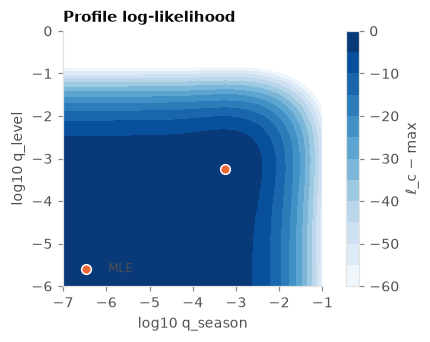

In [3]:
cfg = load_config(); kcfg = cfg["models"]["kalman"]
panel = load_panel(cfg)
origin = forecast_origins(cfg)[-1]
info = panel.truncate(origin)
m = panel.meta
i = int(np.flatnonzero((m["demand_class"] == "smooth").to_numpy() & (info.stockout.sum(1) > 5))[3])
zi = np.log1p(observed_history(info)[i:i+1, -kcfg["fit_window"]:].astype(float))
print(m.loc[i, ["id", "demand_class"]].to_dict(), " observed days:", int((~np.isnan(zi)).sum()))

# profile-likelihood surface over the grid
g1, g2 = np.logspace(-6, 0, 25), np.logspace(-7, -1, 25)
surf = np.array([[profile_loglik(kalman_filter(zi, np.array([a, b])))[0][0] for b in g2] for a in g1])
q_hat, _ = fit_ratios(zi, kcfg)
fig, ax = plt.subplots(figsize=(3.8, 3.0))
cs = ax.contourf(np.log10(g2), np.log10(g1), surf - surf.max(), levels=np.linspace(-60, 0, 13), cmap="Blues")
ax.scatter(np.log10(q_hat[0, 1]), np.log10(q_hat[0, 0]), color="#eb6834", s=40, edgecolor="white", zorder=3, label="MLE")
ax.set_xlabel("log10 q_season"); ax.set_ylabel("log10 q_level"); ax.set_title("Profile log-likelihood")
fig.colorbar(cs, ax=ax, label="ℓ_c − max"); ax.legend(loc="lower left"); ax.grid(False)
plots.save(fig, FIG / "kalman_profile_likelihood.pdf")
print("MLE ratios: q_level = %.2e, q_season = %.2e" % tuple(q_hat[0]))

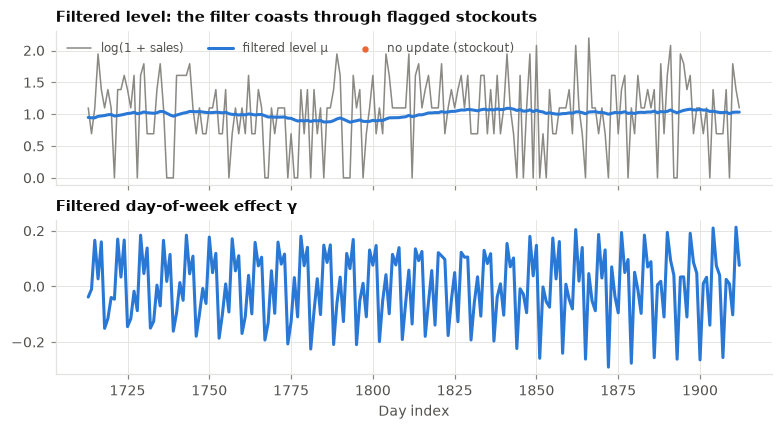

In [4]:
res = kalman_filter(zi, q_hat[0], 1.0, return_path=True)
_, s2 = profile_loglik(res)
days = np.arange(origin - zi.shape[1], origin)[-200:]
fig, axes = plt.subplots(2, 1, figsize=(7, 3.8), sharex=True)
axes[0].plot(days, zi[0, -200:], color=plots.INK_3, lw=1, label="log(1 + sales)")
axes[0].plot(days, res["level"][0, -200:], color="#2a78d6", label="filtered level μ")
gap = np.isnan(zi[0, -200:])
axes[0].scatter(days[gap], res["level"][0, -200:][gap], color="#eb6834", s=10, zorder=3, label="no update (stockout)")
axes[0].legend(loc="upper left", ncols=3); axes[0].set_title("Filtered level: the filter coasts through flagged stockouts")
axes[1].plot(days, res["season"][0, -200:], color="#2a78d6"); axes[1].set_title("Filtered day-of-week effect γ")
axes[1].set_xlabel("Day index")
plots.save(fig, FIG / "kalman_states.pdf")

## 5. Forecast distribution
The $h$-step predictive distribution of $z$ is Gaussian with mean $Z T^{h-1} a_{T+1}$ and variance $\hat\sigma^2_\varepsilon(Z P_{T+h} Z^\top + 1)$. Quantiles **commute with monotone transforms**, so predictive quantiles of $y$ are $\exp(\text{quantile of } z)-1$ exactly. The mean is the log-normal mean $\exp(m + s^2/2) - 1$. That is why the mean is used for RMSE and the median for MAE/WAPE.

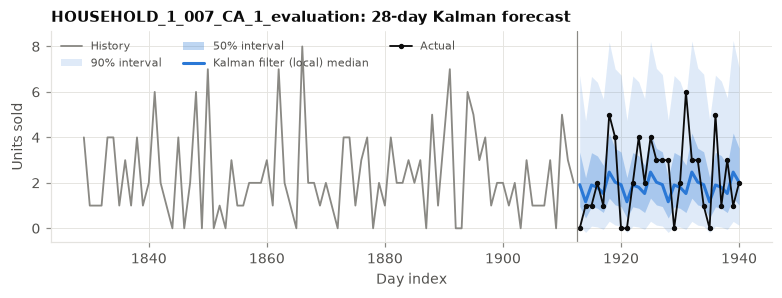

In [5]:
H, levels = 28, np.array(cfg["quantiles"])
mean, var = forecast_from_state(res["a"], res["P"], q_hat, s2, H)
qz = mean[0][:, None] + np.sqrt(var[0])[:, None] * norm.ppf(levels)[None]
fc = pd.DataFrame(np.expm1(qz), columns=[f"q_{a:.2f}" for a in levels]); fc["h"] = np.arange(1, H + 1)
fig, ax = plt.subplots(figsize=(7, 2.6))
plots.fan_chart(panel.y[i, origin-84:origin], panel.y[i, origin:origin+H], fc, "kalman", origin, ax=ax,
                stockout_hist=info.stockout[i, origin-84:origin], title=f"{m.loc[i, 'id']}: 28-day Kalman forecast")
ax.legend(loc="upper left", ncols=3, fontsize=7)
plots.save(fig, FIG / "kalman_fan.pdf")

## 6. What the filter learns across the sample
The fitted signal-to-noise ratios summarise how quickly each SKU's level moves. For most series the MLE of $q_\omega$ sits at the lower edge of the grid, so the **weekly pattern is effectively deterministic** and the data do not support a time-varying seasonal effect. The level ratio $q_\eta$ is largest for smooth/erratic series (fast-moving levels) and smallest for intermittent ones, where the filter averages over long windows. Note that **each SKU is estimated in isolation**: nothing learned for one item helps another. This is the gap the global model targets.

,log_q_level,log_q_season
demand_class,,
erratic,-2.25,-7.5
intermittent,-3.75,-7.5
lumpy,-3.25,-7.5
new,-3.50,-2.0
smooth,-2.75,-7.5


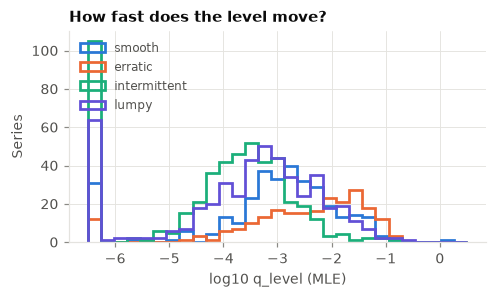

In [6]:
q_all, _ = fit_ratios(np.log1p(observed_history(info)[:, -kcfg["fit_window"]:].astype(float)), kcfg)
qa = m.assign(log_q_level=np.log10(q_all[:, 0]), log_q_season=np.log10(q_all[:, 1]))
display(qa.groupby("demand_class")[["log_q_level", "log_q_season"]].median().round(2))
fig, ax = plt.subplots(figsize=(4.4, 2.6))
klass_colors = {"smooth": "#2a78d6", "erratic": "#eb6834", "intermittent": "#1baf7a", "lumpy": "#6250d6"}
bins = np.linspace(-6.5, 0.5, 30)
for k, c in klass_colors.items():
    ax.hist(qa.loc[qa["demand_class"] == k, "log_q_level"], bins=bins, histtype="step", lw=1.8, color=c, label=k)
ax.set_xlabel("log10 q_level (MLE)"); ax.set_ylabel("Series"); ax.set_title("How fast does the level move?")
ax.legend(loc="upper left")
plots.save(fig, FIG / "kalman_q_by_class.pdf")